In [ ]:
import numpy as np
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

In [ ]:
# Temperature dataset from the lecture
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

In [ ]:
# Normalized input like in the lecture
t_un = 0.1 * t_u

In [ ]:
# Linear model from the lecture
def model_linear(t_u, w, b):
    return w * t_u + b

In [ ]:
# 1.a) Non-linear model: w2 * t_u^2 + w1 * t_u + b
def model(t_u, w2, w1, b):
    return w2 * t_u ** 2 + w1 * t_u + b

def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c) ** 2
    return squared_diffs.mean()

In [ ]:
# Training loop from the lecture, the model is now passed as an argument
# The loss of every epoch is saved for the plot
def training_loop(n_epochs, optimizer, params, t_u, t_c, model):
    loss_history = []
    for epoch in range(1, n_epochs + 1):
        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())
        if epoch % 500 == 0:
            print('Epoch %d, Loss %f' % (epoch, loss.item()))

    return params, loss_history

In [ ]:
# Baseline: linear model from the lecture (lr = 1e-2, 5000 epochs)
print('--- Linear model (lecture) ---')
params_linear = torch.tensor([1.0, 0.0], requires_grad=True)
optimizer = optim.SGD([params_linear], lr=1e-2)
params_linear, history_linear = training_loop(5000, optimizer, params_linear, t_un, t_c, model_linear)
print('Parameters (w, b):', params_linear.data)

--- Linear model (lecture) ---
Epoch 500, Loss 7.860120
Epoch 1000, Loss 3.828538
Epoch 1500, Loss 3.092191
Epoch 2000, Loss 2.957698
Epoch 2500, Loss 2.933134
Epoch 3000, Loss 2.928648
Epoch 3500, Loss 2.927830
Epoch 4000, Loss 2.927679
Epoch 4500, Loss 2.927652
Epoch 5000, Loss 2.927647
Parameters (w, b): tensor([  5.3671, -17.3012])


In [ ]:
# 1.b) Non-linear model with four different learning rates, 5000 epochs each
learning_rates = [0.1, 0.01, 0.001, 0.0001]
results = {}

for lr in learning_rates:
    print(f'\n--- Non-linear model, learning rate = {lr} ---')
    params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)   # w2, w1, b
    optimizer = optim.SGD([params], lr=lr)
    params, history = training_loop(5000, optimizer, params, t_un, t_c, model)
    results[lr] = {'params': params, 'history': history}

    # Find the first epoch where the loss is no longer a finite number
    not_finite = [i for i, l in enumerate(history) if not np.isfinite(l)]
    if not_finite:
        print(f'Diverged: the loss is inf/nan after epoch {not_finite[0] + 1}')
    else:
        print('Parameters (w2, w1, b):', params.data)


--- Non-linear model, learning rate = 0.1 ---
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
Diverged: the loss is inf/nan after epoch 9

--- Non-linear model, learning rate = 0.01 ---
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
Diverged: the loss is inf/nan after epoch 14

--- Non-linear model, learning rate = 0.001 ---
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
Diverged: the loss is inf/nan after epoch 136

--- Non-linear model, learning rate = 0.0001 ---
Epoch 500, Loss 10.708596
Epoch 1000, Loss 8

In [ ]:
# 1.c) Best non-linear model = lowest final loss (diverged runs excluded)
best_lr = min([lr for lr in learning_rates if np.isfinite(results[lr]['history'][-1])],
              key=lambda lr: results[lr]['history'][-1])
params_best = results[best_lr]['params']
print(f'\nBest non-linear model: learning rate = {best_lr}, final loss = {results[best_lr]["history"][-1]:.4f}')
print(f'Linear model (lecture): final loss = {history_linear[-1]:.4f}')


Best non-linear model: learning rate = 0.0001, final loss = 3.8617
Linear model (lecture): final loss = 2.9276


In [ ]:
# Reference: lowest possible loss of a quadratic model (least squares fit)
coeffs = np.polyfit(t_un.numpy(), t_c.numpy(), 2)
print(f'Lowest possible loss of a quadratic model: {np.mean((np.polyval(coeffs, t_un.numpy()) - t_c.numpy()) ** 2):.4f}')

Lowest possible loss of a quadratic model: 2.0907


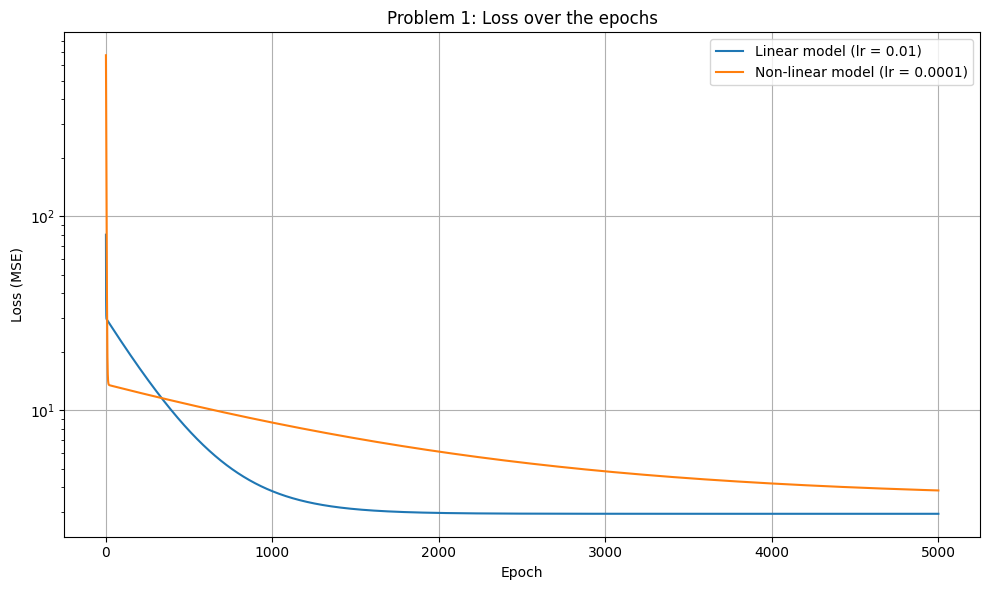

In [ ]:
# Plot the loss over the epochs (best non-linear model and linear model)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 5001), history_linear, label='Linear model (lr = 0.01)')
plt.plot(range(1, 5001), results[best_lr]['history'], label=f'Non-linear model (lr = {best_lr})')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Problem 1: Loss over the epochs')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('problem_1_loss.png', dpi=110)
plt.show()

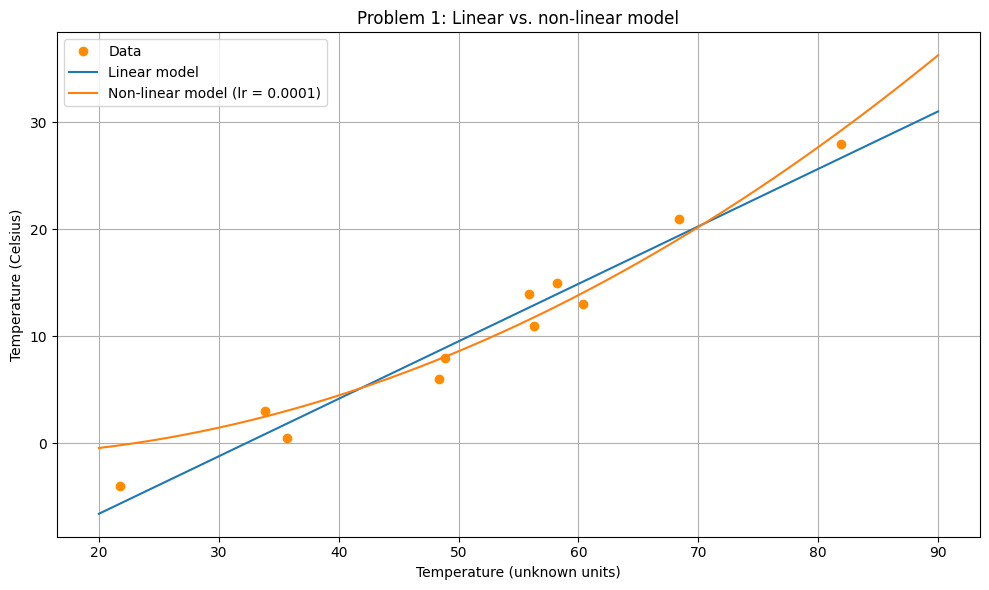

In [ ]:
# Visualize the non-linear model against the linear model over the input dataset (like in the lecture)
t_range = torch.linspace(20.0, 90.0, 200)
with torch.no_grad():
    t_p_linear = model_linear(0.1 * t_range, *params_linear)
    t_p_nonlinear = model(0.1 * t_range, *params_best)

plt.figure(figsize=(10, 6))
plt.plot(t_u.numpy(), t_c.numpy(), 'o', color='darkorange', label='Data')
plt.plot(t_range.numpy(), t_p_linear.numpy(), label='Linear model')
plt.plot(t_range.numpy(), t_p_nonlinear.numpy(), label=f'Non-linear model (lr = {best_lr})')
plt.xlabel('Temperature (unknown units)')
plt.ylabel('Temperature (Celsius)')
plt.title('Problem 1: Linear vs. non-linear model')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('problem_1_models.png', dpi=110)
plt.show()